In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels as sm
from scipy.stats import t
import seaborn as sns

## Data

In [2]:
tips = pd.read_csv('./seaborn_tips.csv')

In [3]:
tips

,bill,tip,guests
0,16.99,1.01,2
1,10.34,1.66,3
2,21.01,3.50,3
3,23.68,3.31,2
4,24.59,3.61,4
...,...,...,...
239,29.03,5.92,3
240,27.18,2.00,2
241,22.67,2.00,2
242,17.82,1.75,2


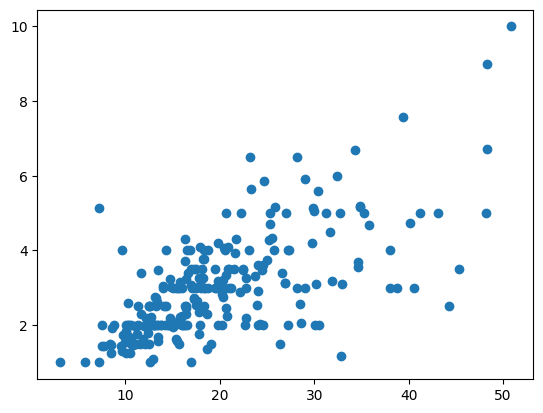

In [4]:
plt.plot(tips.bill, tips.tip, linewidth=0, marker='o')

<Axes: xlabel='guests', ylabel='None'>

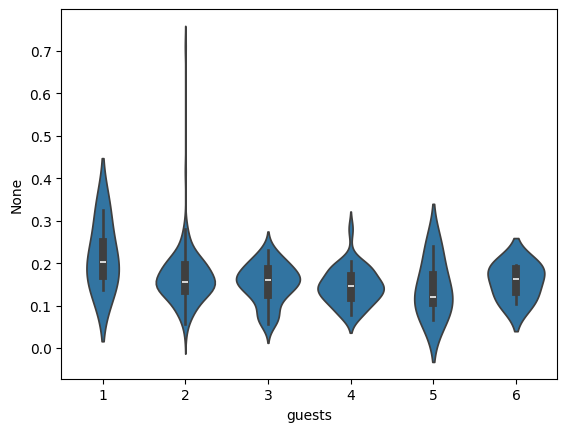

In [5]:
sns.violinplot(x=tips.guests, y=tips.tip/tips.bill)

## Splitting and Fitting

In [6]:
X = tips['bill'].to_numpy()
y = tips['tip'].to_numpy()

split = int(0.8 * len(X))

X_train = X[:split]
y_train = y[:split]

X_test = X[split:]
y_test = y[split:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 195
Testing samples: 49


In [7]:
# (intercept + independent variable) 
X_matrix = np.column_stack((
    np.ones(len(X_train)),
    X_train
))

# OLS solution
beta = np.linalg.inv(X_matrix.T @ X_matrix) @ X_matrix.T @ y_train

intercept = beta[0]
slope = beta[1]

print("Intercept:", intercept)
print("Slope:", slope)

Intercept: 0.9640559332860834
Slope: 0.10495327187726558


In [8]:
y_train_pred = intercept + slope * X_train
y_test_pred = intercept + slope * X_test

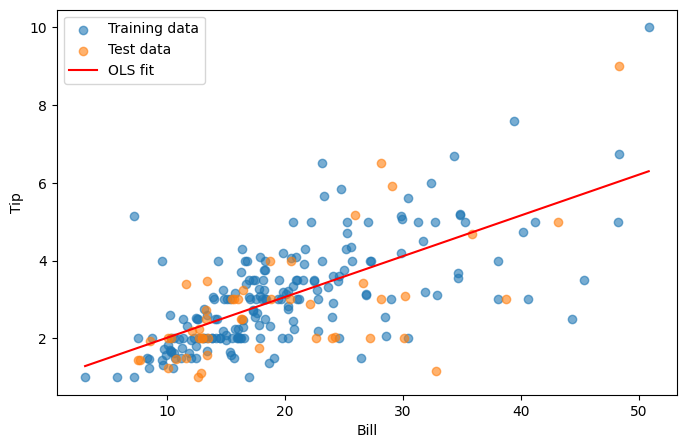

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train, y_train, alpha=0.6, label='Training data')
plt.scatter(X_test, y_test, alpha=0.6, label='Test data')

x_line = np.linspace(X.min(), X.max(), 100)
y_line = intercept + slope * x_line

plt.plot(x_line, y_line, color='red', label='OLS fit')

plt.xlabel("Bill")
plt.ylabel("Tip")
plt.legend()

In [10]:
# for a 30 euro bill 
tip_30 = intercept + 30*slope
tip_30

4.11265408960405

In [11]:
def evaluate(y_true, y_pred):

    residuals = y_true - y_pred

    # Mean squared error
    mse = np.mean(residuals**2)

    # Root mean squared error
    rmse = np.sqrt(mse)

    # Mean absolute error
    mae = np.mean(np.abs(residuals))

    # R-squared
    ss_res = np.sum(residuals**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)

    r2 = 1 - ss_res / ss_tot

    return mse, rmse, mae, r2


train_metrics = evaluate(y_train, y_train_pred)
test_metrics = evaluate(y_test, y_test_pred)

print("TRAINING PERFORMANCE")
print(f"MSE:  {train_metrics[0]:.4f}")
print(f"RMSE: {train_metrics[1]:.4f}")
print(f"MAE:  {train_metrics[2]:.4f}")
print(f"R²:   {train_metrics[3]:.4f}")

print("\nTEST PERFORMANCE")
print(f"MSE:  {test_metrics[0]:.4f}")
print(f"RMSE: {test_metrics[1]:.4f}")
print(f"MAE:  {test_metrics[2]:.4f}")
print(f"R²:   {test_metrics[3]:.4f}")

TRAINING PERFORMANCE
MSE:  0.9655
RMSE: 0.9826
MAE:  0.7268
R²:   0.4662

TEST PERFORMANCE
MSE:  1.3256
RMSE: 1.1514
MAE:  0.8443
R²:   0.4097


## Fitting higher degree polynomials

In [12]:
# now fitting higher degree polynomials 

degrees = [1, 2, 3, 5, 10, 15]

train_mse = []
test_mse = []

models = []

for degree in degrees:

    # Construct polynomial design matrices
    X_train_poly = np.vander(X_train, degree + 1, increasing=True)
    X_test_poly = np.vander(X_test, degree + 1, increasing=True)

    # Estimate coefficients using least squares
    beta = np.linalg.lstsq(X_train_poly, y_train, rcond=None)[0]

    # Predictions
    y_train_pred = X_train_poly @ beta
    y_test_pred = X_test_poly @ beta

    # Calculate MSE
    mse_train = np.mean((y_train - y_train_pred)**2)
    mse_test = np.mean((y_test - y_test_pred)**2)

    train_mse.append(mse_train)
    test_mse.append(mse_test)

    models.append(beta)

    print(f"Degree {degree:2d}: "
          f"Train MSE = {mse_train:.4f}, "
          f"Test MSE = {mse_test:.4f}")

Degree  1: Train MSE = 0.9655, Test MSE = 1.3256
Degree  2: Train MSE = 0.9617, Test MSE = 1.3554
Degree  3: Train MSE = 0.9501, Test MSE = 1.2700
Degree  5: Train MSE = 0.8521, Test MSE = 1.3109
Degree 10: Train MSE = 1.0486, Test MSE = 1.6028
Degree 15: Train MSE = 3.5782, Test MSE = 3.9947


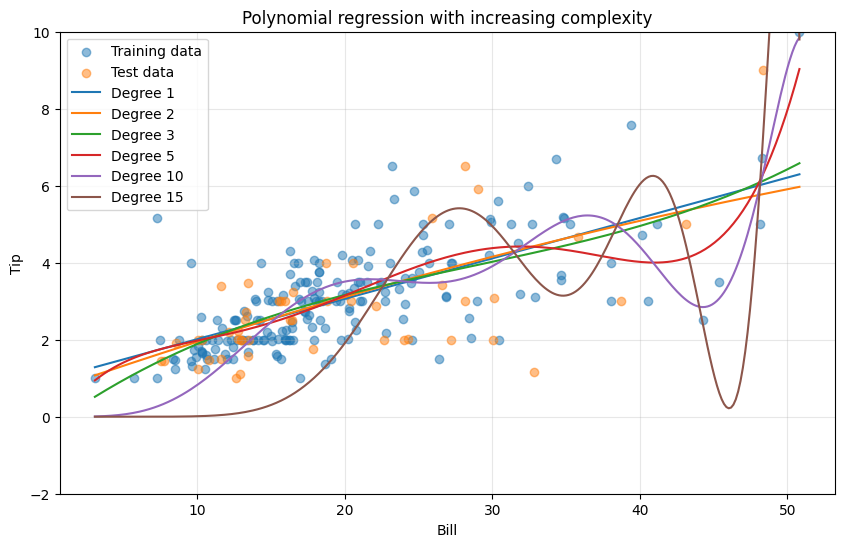

In [13]:
plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.5, label='Training data')
plt.scatter(X_test, y_test, alpha=0.5, label='Test data')

x_plot = np.linspace(X.min(), X.max(), 300)

for degree, beta in zip(degrees, models):

    X_plot_poly = np.vander(x_plot, degree + 1, increasing=True)

    y_plot = X_plot_poly @ beta

    plt.plot(x_plot, y_plot, label=f'Degree {degree}')

plt.xlabel("Bill")
plt.ylabel("Tip")
plt.title("Polynomial regression with increasing complexity")

plt.legend()
plt.ylim(-2, 10)
plt.grid(alpha=0.3)

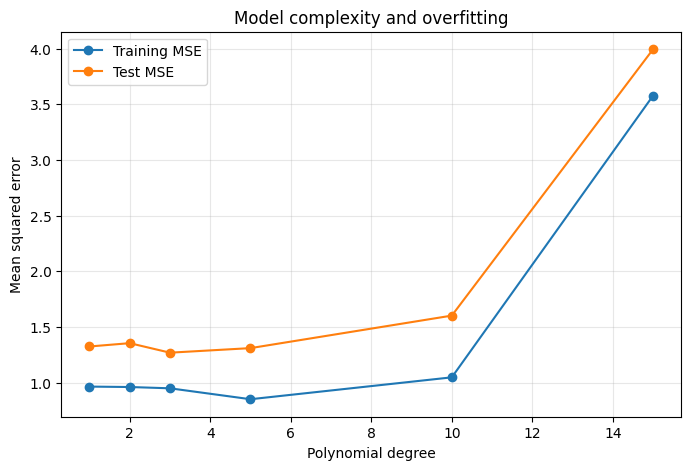

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(degrees, train_mse, 'o-', label='Training MSE')
plt.plot(degrees, test_mse, 'o-', label='Test MSE')

plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error")
plt.title("Model complexity and overfitting")

plt.legend()
plt.grid(alpha=0.3)

## Scaling and re-fitting

In [15]:
# Scale bill values to approximately [-1, 1]
x_min = X_train.min()
x_max = X_train.max()

X_train_scaled = 2 * (X_train - x_min) / (x_max - x_min) - 1
X_test_scaled = 2 * (X_test - x_min) / (x_max - x_min) - 1

degrees = [1, 2, 3, 5, 10, 15]

train_mse = []
test_mse = []

models = []

for degree in degrees:

    X_train_poly = np.vander(
        X_train_scaled, degree + 1, increasing=True
    )

    X_test_poly = np.vander(
        X_test_scaled, degree + 1, increasing=True
    )

    beta = np.linalg.lstsq(
        X_train_poly, y_train, rcond=None
    )[0]

    y_train_pred = X_train_poly @ beta
    y_test_pred = X_test_poly @ beta

    train_mse.append(np.mean((y_train - y_train_pred)**2))
    test_mse.append(np.mean((y_test - y_test_pred)**2))

    models.append(beta)
    print(f"Degree {degree:2d}: "
          f"Train MSE = {mse_train:.4f}, "
          f"Test MSE = {mse_test:.4f}")

Degree  1: Train MSE = 3.5782, Test MSE = 3.9947
Degree  2: Train MSE = 3.5782, Test MSE = 3.9947
Degree  3: Train MSE = 3.5782, Test MSE = 3.9947
Degree  5: Train MSE = 3.5782, Test MSE = 3.9947
Degree 10: Train MSE = 3.5782, Test MSE = 3.9947
Degree 15: Train MSE = 3.5782, Test MSE = 3.9947


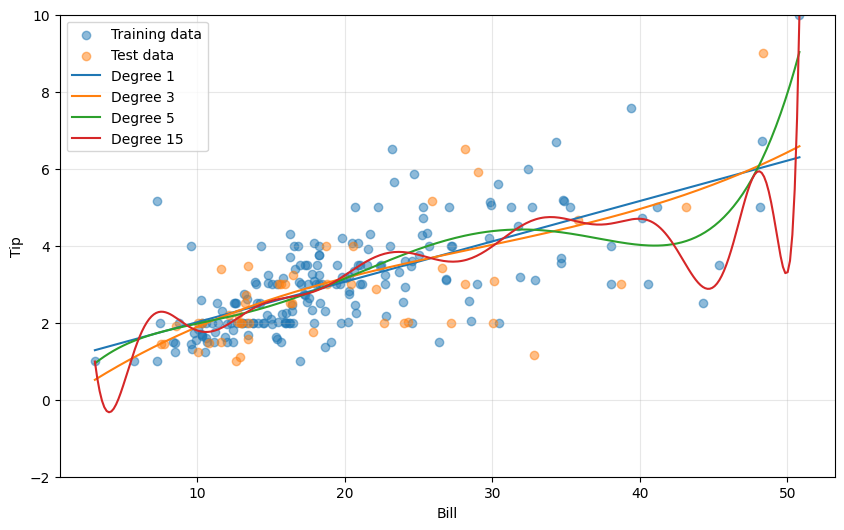

In [16]:
selected_degrees = [1, 3, 5, 15]

plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.5, label='Training data')
plt.scatter(X_test, y_test, alpha=0.5, label='Test data')

x_plot = np.linspace(-1, 1, 300)

for degree, beta in zip(degrees, models):

    if degree not in selected_degrees:
        continue

    X_plot_poly = np.vander(
        x_plot, degree + 1, increasing=True
    )

    y_plot = X_plot_poly @ beta

    # Convert scaled x back to original bill values
    x_original = (x_plot + 1) * (x_max - x_min) / 2 + x_min

    plt.plot(x_original, y_plot, label=f'Degree {degree}')

plt.xlabel("Bill")
plt.ylabel("Tip")
plt.ylim(-2, 10)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

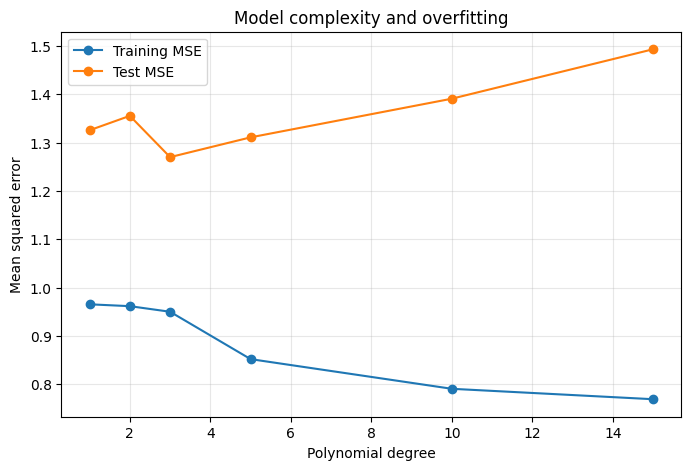

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(degrees, train_mse, 'o-', label='Training MSE')
plt.plot(degrees, test_mse, 'o-', label='Test MSE')

plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error")
plt.title("Model complexity and overfitting")

plt.legend()
plt.grid(alpha=0.3)

## Bias-Variance

In [18]:
np.random.seed(42)

# Use the actual bill distribution from Tips
bill_values = tips['bill'].to_numpy()

# Known underlying relationship
def true_function(x):
    return 1 + 0.12*x + 0.002*x**2

noise_sigma = 0.8

# Fixed evaluation points
x_eval = np.linspace(bill_values.min(), bill_values.max(), 100)

# Scale x to [-1, 1]
x_min = bill_values.min()
x_max = bill_values.max()

def scale_x(x):
    return 2 * (x - x_min) / (x_max - x_min) - 1

x_eval_scaled = scale_x(x_eval)

degrees = [1, 2, 3, 5, 10, 15]

n_simulations = 200
n_train = 180

bias_squared = []
variance = []
expected_error = []

for degree in degrees:

    predictions = []

    for _ in range(n_simulations):

        # Generate a new training sample
        x_train_sim = np.random.choice(
            bill_values, size=n_train, replace=True
        )

        # Generate noisy response
        y_train_sim = (
            true_function(x_train_sim)
            + np.random.normal(0, noise_sigma, n_train)
        )

        # Scale independent variable
        x_train_scaled = scale_x(x_train_sim)

        # Construct polynomial design matrix
        X_train_poly = np.vander(
            x_train_scaled,
            degree + 1,
            increasing=True
        )

        X_eval_poly = np.vander(
            x_eval_scaled,
            degree + 1,
            increasing=True
        )

        # Fit model
        beta = np.linalg.lstsq(
            X_train_poly,
            y_train_sim,
            rcond=None
        )[0]

        # Predictions at fixed evaluation points
        y_pred = X_eval_poly @ beta

        predictions.append(y_pred)

    predictions = np.array(predictions)

    # Average prediction across simulations
    mean_prediction = np.mean(predictions, axis=0)

    # True underlying function
    y_true = true_function(x_eval)

    # Bias squared
    bias2 = np.mean((mean_prediction - y_true)**2)

    # Variance of predictions
    var = np.mean(np.var(predictions, axis=0))

    # Expected prediction error
    error = bias2 + var + noise_sigma**2

    bias_squared.append(bias2)
    variance.append(var)
    expected_error.append(error)

    print(
        f"Degree {degree:2d}: "
        f"Bias² = {bias2:.4f}, "
        f"Variance = {var:.4f}, "
        f"Expected error = {error:.4f}"
    )

Degree  1: Bias² = 0.1771, Variance = 0.0197, Expected error = 0.8368
Degree  2: Bias² = 0.0002, Variance = 0.0325, Expected error = 0.6727
Degree  3: Bias² = 0.0000, Variance = 0.0572, Expected error = 0.6972
Degree  5: Bias² = 0.0001, Variance = 0.2189, Expected error = 0.8590
Degree 10: Bias² = 0.0785, Variance = 109.2351, Expected error = 109.9536
Degree 15: Bias² = 4514.0384, Variance = 16660331.7569, Expected error = 16664846.4354


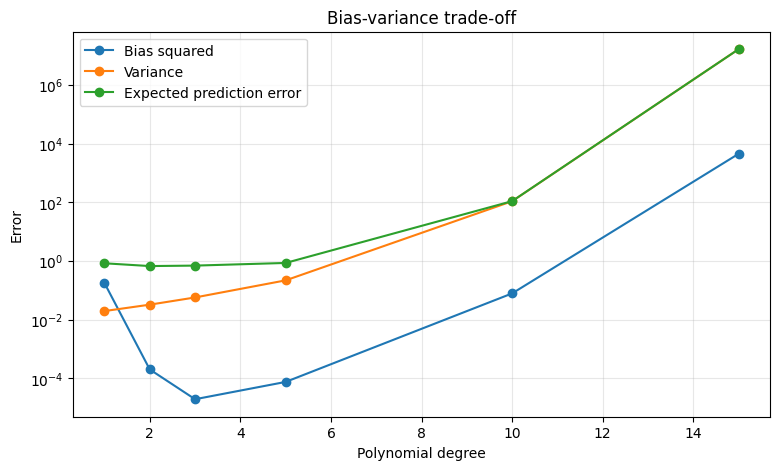

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(degrees, bias_squared, 'o-', label='Bias squared')
plt.plot(degrees, variance, 'o-', label='Variance')
plt.plot(degrees, expected_error, 'o-', label='Expected prediction error')

plt.xlabel("Polynomial degree")
plt.ylabel("Error")
plt.title("Bias-variance trade-off")

plt.legend()
plt.grid(alpha=0.3)
plt.yscale('log')

## Second variable

In [20]:
X = tips[['bill', 'guests']].to_numpy()
y = tips['tip'].to_numpy()

split = int(0.8 * len(X))

X_train = X[:split]
y_train = y[:split]

X_test = X[split:]
y_test = y[split:]

mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)

X_train_scaled = (X_train - mu) / sigma
X_test_scaled = (X_test - mu) / sigma


In [21]:
X_train_design = np.column_stack((
    np.ones(len(X_train)),
    X_train_scaled
))

X_test_design = np.column_stack((
    np.ones(len(X_test)),
    X_test_scaled
))

# OLS estimation
beta = np.linalg.lstsq(
    X_train_design,
    y_train,
    rcond=None
)[0]

print("Intercept:", beta[0])
print("Bill coefficient:", beta[1])
print("Guests coefficient:", beta[2])

Intercept: 3.048923076923077
Bill coefficient: 0.8278563646219538
Guests coefficient: 0.15558564504564193


In [22]:
y_train_pred = X_train_design @ beta
y_test_pred = X_test_design @ beta

train_metrics = evaluate(y_train, y_train_pred)
test_metrics = evaluate(y_test, y_test_pred)

print("TRAINING PERFORMANCE")
print(f"MSE:  {train_metrics[0]:.4f}")
print(f"RMSE: {train_metrics[1]:.4f}")
print(f"MAE:  {train_metrics[2]:.4f}")
print(f"R²:   {train_metrics[3]:.4f}")

print("\nTEST PERFORMANCE")
print(f"MSE:  {test_metrics[0]:.4f}")
print(f"RMSE: {test_metrics[1]:.4f}")
print(f"MAE:  {test_metrics[2]:.4f}")
print(f"R²:   {test_metrics[3]:.4f}")

TRAINING PERFORMANCE
MSE:  0.9495
RMSE: 0.9744
MAE:  0.7209
R²:   0.4750

TEST PERFORMANCE
MSE:  1.2856
RMSE: 1.1339
MAE:  0.8326
R²:   0.4275


## significance and confidence

In [23]:
# Number of observations and parameters
n = len(y_train)
p = X_train_design.shape[1]

# Residuals
residuals = y_train - y_train_pred

# Residual sum of squares
RSS = np.sum(residuals**2)

# Estimate of error variance
sigma2 = RSS / (n - p)

# Covariance matrix of beta
cov_beta = sigma2 * np.linalg.inv(
    X_train_design.T @ X_train_design
)

print("Covariance matrix:")
print(cov_beta)

Covariance matrix:
[[ 4.94509091e-03 -8.07319916e-19  1.93293399e-18]
 [-8.07319916e-19  7.46238345e-03 -4.33416684e-03]
 [ 1.93293399e-18 -4.33416684e-03  7.46238345e-03]]


In [24]:
se_beta = np.sqrt(np.diag(cov_beta))

print("Standard errors:")
print(se_beta)

Standard errors:
[0.07032134 0.08638509 0.08638509]


In [25]:


# Degrees of freedom
df = n - p

# t-statistics
t_stats = beta / se_beta

# Two-sided p-values
p_values = 2 * t.sf(np.abs(t_stats), df)

print("t-statistics:", t_stats)
print("p-values:", p_values)

t-statistics: [43.35701028  9.58332488  1.80107063]
p-values: [4.05069194e-101 5.03522188e-018 7.32609457e-002]


In [26]:
# Critical t-value for 95% confidence
t_critical = t.ppf(0.975, df)

# Confidence intervals
lower = beta - t_critical * se_beta
upper = beta + t_critical * se_beta

for name, b, se, pval, lo, hi in zip(
    ['Intercept', 'Bill', 'Guests'],
    beta, se_beta, p_values, lower, upper
):
    print(f"\n{name}")
    print(f"Coefficient: {b:.4f}")
    print(f"Standard error: {se:.4f}")
    print(f"p-value: {pval}")
    print(f"95% CI: [{lo:.4f}, {hi:.4f}]")


Intercept
Coefficient: 3.0489
Standard error: 0.0703
p-value: 4.0506919378197874e-101
95% CI: [2.9102, 3.1876]

Bill
Coefficient: 0.8279
Standard error: 0.0864
p-value: 5.035221879602727e-18
95% CI: [0.6575, 0.9982]

Guests
Coefficient: 0.1556
Standard error: 0.0864
p-value: 0.07326094572047397
95% CI: [-0.0148, 0.3260]


## Bayesian inference of coefficients

In [27]:
x = tips['bill'].to_numpy()
y = tips['tip'].to_numpy()

# Standardise bill
x_mean = np.mean(x)
x_std = np.std(x)

x_scaled = (x - x_mean) / x_std

# Design matrix
X = np.column_stack((
    np.ones(len(x)),
    x_scaled
))

In [28]:
mu_prior = np.array([0.0, 0.0])

Sigma_prior = np.array([
    [100.0, 0.0],
    [0.0, 4.0]
])

sigma = 1.0

In [29]:
Sigma_post = np.linalg.inv(
    np.linalg.inv(Sigma_prior)
    + (X.T @ X) / sigma**2
)

mu_post = Sigma_post @ (
    np.linalg.inv(Sigma_prior) @ mu_prior
    + (X.T @ y) / sigma**2
)

print("Posterior mean:")
print(mu_post)

print("\nPosterior covariance:")
print(Sigma_post)

print("\nPosterior standard deviations:")
print(np.sqrt(np.diag(Sigma_post)))

Posterior mean:
[2.99815581 0.93209861]

Posterior covariance:
[[4.09819270e-03 3.27854161e-19]
 [3.27854161e-19 4.09416581e-03]]

Posterior standard deviations:
[0.06401713 0.06398567]


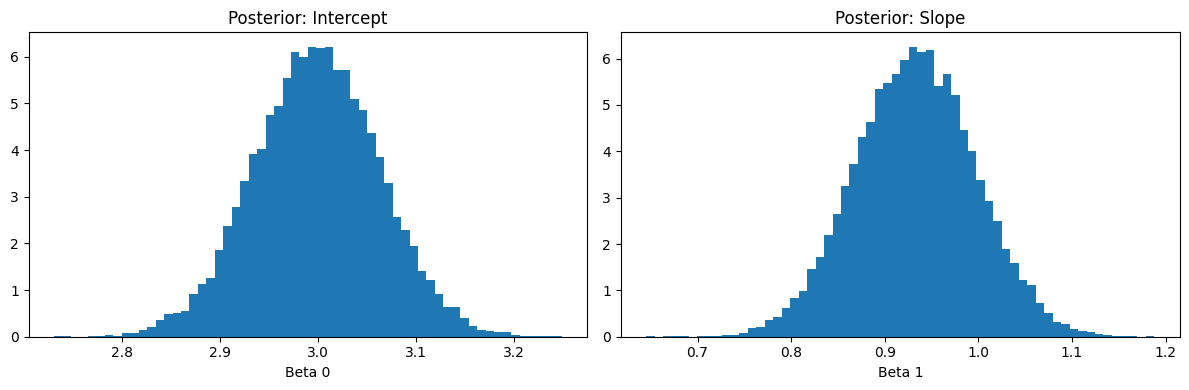

In [30]:
posterior_samples = np.random.multivariate_normal(
    mu_post,
    Sigma_post,
    size=20000
)

beta0_samples = posterior_samples[:, 0]
beta1_samples = posterior_samples[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(beta0_samples, bins=60, density=True)
axes[0].set_title("Posterior: Intercept")
axes[0].set_xlabel("Beta 0")

axes[1].hist(beta1_samples, bins=60, density=True)
axes[1].set_title("Posterior: Slope")
axes[1].set_xlabel("Beta 1")

plt.tight_layout()
plt.show()

In [31]:
for i, name in enumerate(['Intercept', 'Slope']):

    mean = mu_post[i]
    sd = np.sqrt(Sigma_post[i, i])

    lower = mean - 1.96 * sd
    upper = mean + 1.96 * sd

    print(f"{name}:")
    print(f"Posterior mean: {mean:.4f}")
    print(f"Posterior SD: {sd:.4f}")
    print(f"95% credible interval: [{lower:.4f}, {upper:.4f}]")

Intercept:
Posterior mean: 2.9982
Posterior SD: 0.0640
95% credible interval: [2.8727, 3.1236]
Slope:
Posterior mean: 0.9321
Posterior SD: 0.0640
95% credible interval: [0.8067, 1.0575]


## Bayesian prediction of a future input

In [32]:
bill_value = 30

x_new = (bill_value - x_mean) / x_std

X_new = np.array([1, x_new])

# Posterior predictive mean of expected tip
pred_mean = X_new @ mu_post

# Posterior variance of expected tip
pred_var = X_new @ Sigma_post @ X_new.T

pred_sd = np.sqrt(pred_var)

print("Expected tip:", pred_mean)
print("Posterior SD:", pred_sd)

print("95% credible interval:")
print([
    pred_mean - 1.96 * pred_sd,
    pred_mean + 1.96 * pred_sd
])

Expected tip: 4.069784279860781
Posterior SD: 0.09751845375415065
95% credible interval:
[3.878648110502646, 4.260920449218917]


In [33]:
# Predictive variance includes observational noise
predictive_var = pred_var + sigma**2

predictive_sd = np.sqrt(predictive_var)

print("Predicted tip:", pred_mean)

print("95% prediction interval:")
print([
    pred_mean - 1.96 * predictive_sd,
    pred_mean + 1.96 * predictive_sd
])

Predicted tip: 4.069784279860781
95% prediction interval:
[2.100486680401293, 6.039081879320269]


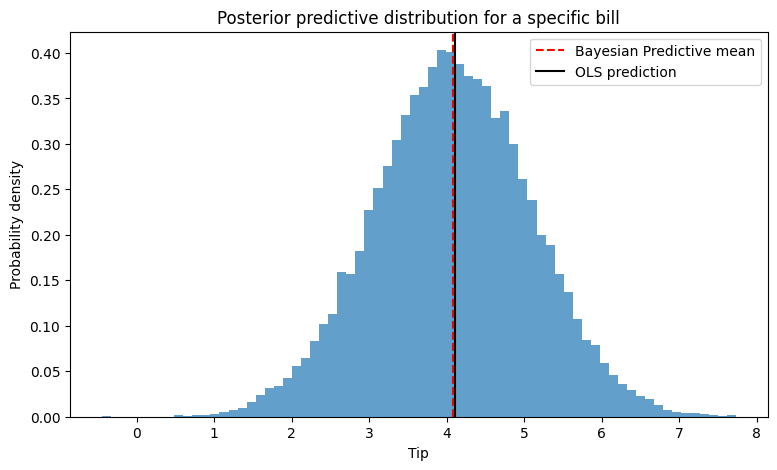

Predictive mean: 4.0768560216819685
95% prediction interval: [2.08057086 6.04120354]


In [34]:
# Draw coefficient samples from the posterior
beta_samples = np.random.multivariate_normal(
    mu_post,
    Sigma_post,
    size=20000
)

# Expected tip for each coefficient sample
expected_tips = beta_samples @ X_new

# Add observational noise
predicted_tips = (
    expected_tips
    + np.random.normal(0, sigma, len(expected_tips))
)

plt.figure(figsize=(9, 5))

plt.hist(
    predicted_tips,
    bins=70,
    density=True,
    alpha=0.7
)

plt.axvline(
    np.mean(predicted_tips),
    color='red',
    linestyle='--',
    label='Bayesian Predictive mean'
)
plt.axvline(tip_30, color='black', label='OLS prediction')

plt.xlabel("Tip")
plt.ylabel("Probability density")
plt.title("Posterior predictive distribution for a specific bill")

plt.legend()
plt.show()

print("Predictive mean:", np.mean(predicted_tips))
print("95% prediction interval:",
      np.percentile(predicted_tips, [2.5, 97.5]))